In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import shap

c:\Users\sahasrapathi\Desktop\explainable_ai_project\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
from pathlib import Path

file_path = Path.cwd() / "data" / "raw" / "StudentPerformanceFactors.csv"

if not file_path.exists():
    file_path = Path.cwd().parent / "data" / "raw" / "StudentPerformanceFactors.csv"

print("Dataset path:", file_path)
print("File exists:", file_path.exists())

Dataset path: c:\Users\sahasrapathi\Desktop\explainable_ai_project\data\raw\StudentPerformanceFactors.csv
File exists: True


In [4]:
df = pd.read_csv("../data/raw/StudentPerformanceFactors.csv")


NameError: name 'pd' is not defined

In [ ]:
import pandas as pd



In [ ]:
df = pd.read_csv("../data/raw/StudentPerformanceFactors.csv")

In [ ]:
df.head()

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [ ]:
df.shape

(6607, 20)

In [ ]:
df.columns

Index(['Hours_Studied', 'Attendance', 'Parental_Involvement',
       'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours',
       'Previous_Scores', 'Motivation_Level', 'Internet_Access',
       'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type',
       'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities',
       'Parental_Education_Level', 'Distance_from_Home', 'Gender',
       'Exam_Score'],
      dtype='str')

In [ ]:
df.dtypes

Hours_Studied                 int64
Attendance                    int64
Parental_Involvement            str
Access_to_Resources             str
Extracurricular_Activities      str
Sleep_Hours                   int64
Previous_Scores               int64
Motivation_Level                str
Internet_Access                 str
Tutoring_Sessions             int64
Family_Income                   str
Teacher_Quality                 str
School_Type                     str
Peer_Influence                  str
Physical_Activity             int64
Learning_Disabilities           str
Parental_Education_Level        str
Distance_from_Home              str
Gender                          str
Exam_Score                    int64
dtype: object

In [ ]:
df.isnull().sum()

Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gender                         0
Exam_Score                     0
dtype: int64

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.describe()

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,7.02906,75.070531,1.493719,2.967610,67.235659
std,5.990594,11.547475,1.46812,14.399784,1.230570,1.031231,3.890456
min,1.000000,60.000000,4.00000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.00000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.00000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.00000,100.000000,8.000000,6.000000,101.000000


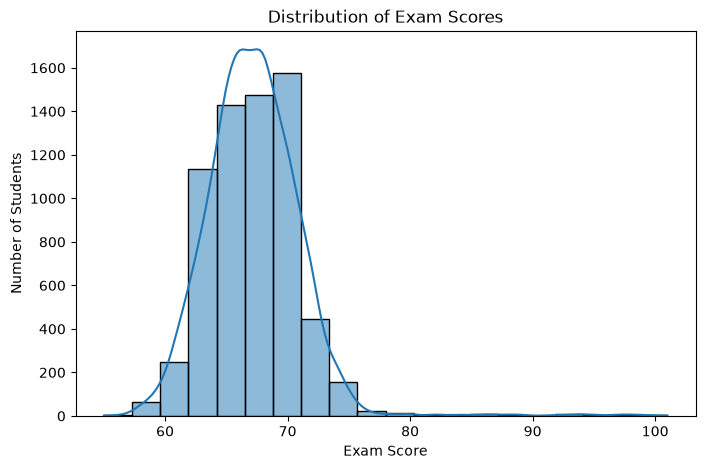

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(df["Exam_Score"], bins=20, kde=True)

plt.title("Distribution of Exam Scores")
plt.xlabel("Exam Score")
plt.ylabel("Number of Students")

plt.show()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv("../data/raw/StudentPerformanceFactors.csv")

In [ ]:
df.head()

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


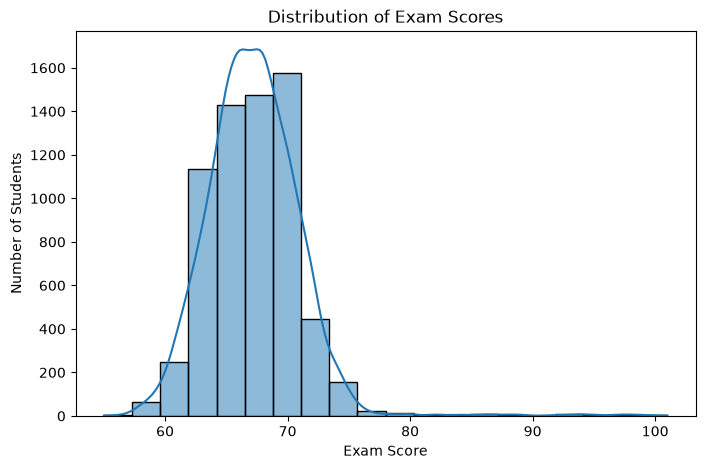

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(df["Exam_Score"], bins=20, kde=True)

plt.title("Distribution of Exam Scores")
plt.xlabel("Exam Score")
plt.ylabel("Number of Students")

plt.show()

In [ ]:
df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

df.head()

Dataset loaded successfully!
Number of rows and columns: (6607, 20)


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [ ]:
print("Dataset columns:")
print(df.columns.tolist())

Dataset columns:
['Hours_Studied', 'Attendance', 'Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours', 'Previous_Scores', 'Motivation_Level', 'Internet_Access', 'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender', 'Exam_Score']


In [ ]:
print("Exam Score Statistics:")
print(df["Exam_Score"].describe())

Exam Score Statistics:
count    6607.000000
mean       67.235659
std         3.890456
min        55.000000
25%        65.000000
50%        67.000000
75%        69.000000
max       101.000000
Name: Exam_Score, dtype: float64


In [ ]:
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gender                         0
Exam_Score                     0
dtype: int64


In [ ]:
print("Dataset shape:", df.shape)
print("\nAll columns:")
print(df.columns.tolist())

Dataset shape: (6607, 20)

All columns:
['Hours_Studied', 'Attendance', 'Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours', 'Previous_Scores', 'Motivation_Level', 'Internet_Access', 'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender', 'Exam_Score']


In [ ]:
missing = df.isnull().sum()

print("Columns with missing values:")
print(missing[missing > 0])

print("\nTotal missing cells:", missing.sum())

Columns with missing values:
Teacher_Quality             78
Parental_Education_Level    90
Distance_from_Home          67
dtype: int64

Total missing cells: 235


In [ ]:
print(df.dtypes)

Hours_Studied                 int64
Attendance                    int64
Parental_Involvement            str
Access_to_Resources             str
Extracurricular_Activities      str
Sleep_Hours                   int64
Previous_Scores               int64
Motivation_Level                str
Internet_Access                 str
Tutoring_Sessions             int64
Family_Income                   str
Teacher_Quality                 str
School_Type                     str
Peer_Influence                  str
Physical_Activity             int64
Learning_Disabilities           str
Parental_Education_Level        str
Distance_from_Home              str
Gender                          str
Exam_Score                    int64
dtype: object


In [ ]:
print("Number of unique exam scores:", df["Exam_Score"].nunique())

print("\nMost frequent exam scores:")
print(df["Exam_Score"].value_counts().head(10))

Number of unique exam scores: 45

Most frequent exam scores:
Exam_Score
68    759
66    751
67    717
65    679
69    624
70    542
64    501
71    408
63    371
72    304
Name: count, dtype: int64


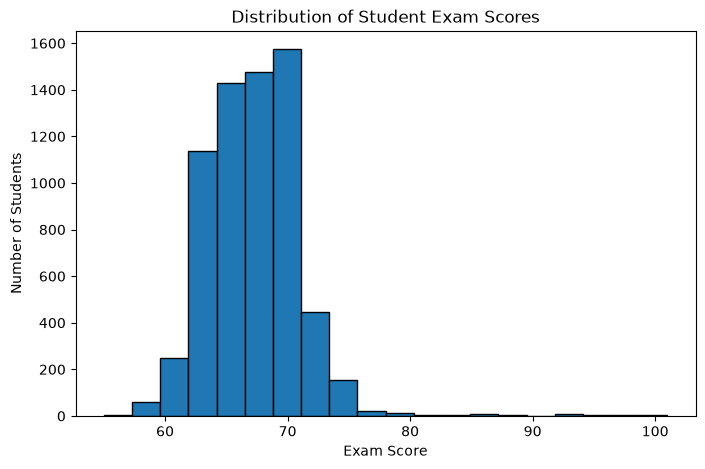

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(df["Exam_Score"], bins=20, edgecolor="black")
plt.xlabel("Exam Score")
plt.ylabel("Number of Students")
plt.title("Distribution of Student Exam Scores")
plt.show()


In [ ]:
correlation = df[
    ["Hours_Studied", "Attendance", "Sleep_Hours",
     "Previous_Scores", "Tutoring_Sessions",
     "Physical_Activity", "Exam_Score"]
].corr()

print(correlation["Exam_Score"].sort_values(ascending=False))

Exam_Score           1.000000
Attendance           0.581072
Hours_Studied        0.445455
Previous_Scores      0.175079
Tutoring_Sessions    0.156525
Physical_Activity    0.027824
Sleep_Hours         -0.017022
Name: Exam_Score, dtype: float64


In [ ]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [ ]:
print("Students with exam scores above 100:")
print(df[df["Exam_Score"] > 100][["Exam_Score"]])

Students with exam scores above 100:
      Exam_Score
1525         101


In [ ]:
print(df.loc[1525])

Hours_Studied                          27
Attendance                             98
Parental_Involvement                  Low
Access_to_Resources                Medium
Extracurricular_Activities            Yes
Sleep_Hours                             6
Previous_Scores                        93
Motivation_Level                      Low
Internet_Access                        No
Tutoring_Sessions                       5
Family_Income                        High
Teacher_Quality                      High
School_Type                        Public
Peer_Influence                   Positive
Physical_Activity                       3
Learning_Disabilities                  No
Parental_Education_Level      High School
Distance_from_Home               Moderate
Gender                             Female
Exam_Score                            101
Name: 1525, dtype: object


In [ ]:
numerical_columns = df.select_dtypes(include="number").columns

print(df[numerical_columns].describe().loc[["min", "max"]])

     Hours_Studied  Attendance  Sleep_Hours  Previous_Scores  \
min            1.0        60.0          4.0             50.0   
max           44.0       100.0         10.0            100.0   

     Tutoring_Sessions  Physical_Activity  Exam_Score  
min                0.0                0.0        55.0  
max                8.0                6.0       101.0  


In [ ]:
print("Students scoring below 60:", (df["Exam_Score"] < 60).sum())
print("Total students:", len(df))

Students scoring below 60: 68
Total students: 6607


In [ ]:
X = df.drop(columns=["Exam_Score"])
y = df["Exam_Score"]

print("Input features shape:", X.shape)
print("Target shape:", y.shape)
print("Target column:", y.name)

Input features shape: (6607, 19)
Target shape: (6607,)
Target column: Exam_Score


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training input shape:", X_train.shape)
print("Testing input shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training input shape: (5285, 19)
Testing input shape: (1322, 19)
Training target shape: (5285,)
Testing target shape: (1322,)


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

numerical_columns = X_train.select_dtypes(include="number").columns
categorical_columns = X_train.select_dtypes(include="str").columns

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numerical", numerical_pipeline, numerical_columns),
    ("categorical", categorical_pipeline, categorical_columns)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)
print("Remaining missing values in training:", 
      __import__("numpy").isnan(X_train_processed.data if hasattr(X_train_processed, "data") else X_train_processed).sum())

Processed training shape: (5285, 40)
Processed testing shape: (1322, 40)
Remaining missing values in training: 0


In [ ]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train_processed, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_pred = model.predict(X_test_processed)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MODEL EVALUATION RESULTS")
print("------------------------")
print("Mean Absolute Error (MAE):", round(mae, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))
print("R² Score:", round(r2, 4))

MODEL EVALUATION RESULTS
------------------------
Mean Absolute Error (MAE): 1.08
Root Mean Squared Error (RMSE): 2.17
R² Score: 0.6682


In [ ]:
comparison = pd.DataFrame({
    "Actual Score": y_test.values,
    "Predicted Score": np.round(y_pred, 2)
})

comparison["Absolute Error"] = np.abs(
    comparison["Actual Score"] - comparison["Predicted Score"]
)

print(comparison.head(10))

   Actual Score  Predicted Score  Absolute Error
0            65            64.64            0.36
1            65            66.38            1.38
2            71            70.52            0.48
3            64            65.89            1.89
4            66            66.20            0.20
5            66            66.52            0.52
6            72            71.47            0.53
7            66            67.03            1.03
8            70            69.47            0.53
9            70            69.78            0.22


In [ ]:
risk_results = pd.DataFrame({
    "Actual Score": y_test.values,
    "Predicted Score": y_pred
})

risk_results["Risk Status"] = np.where(
    risk_results["Predicted Score"] < 60,
    "Potentially At Risk",
    "No Risk Flag"
)

print("Risk flag summary:")
print(risk_results["Risk Status"].value_counts())

print("\nStudents flagged for review:")
print(
    risk_results[risk_results["Risk Status"] == "Potentially At Risk"]
    .head(10)
    .round(2)
)

Risk flag summary:
Risk Status
No Risk Flag           1318
Potentially At Risk       4
Name: count, dtype: int64

Students flagged for review:
      Actual Score  Predicted Score          Risk Status
33              55            58.41  Potentially At Risk
170             59            59.94  Potentially At Risk
814             57            59.49  Potentially At Risk
1114            58            59.79  Potentially At Risk


In [ ]:
actual_at_risk = risk_results["Actual Score"] < 60
predicted_at_risk = risk_results["Predicted Score"] < 60

true_positives = (actual_at_risk & predicted_at_risk).sum()
false_negatives = (actual_at_risk & ~predicted_at_risk).sum()
false_positives = (~actual_at_risk & predicted_at_risk).sum()
true_negatives = (~actual_at_risk & ~predicted_at_risk).sum()

print("Actual low-scoring students:", actual_at_risk.sum())
print("Correctly flagged:", true_positives)
print("Low-scoring students missed:", false_negatives)
print("Students flagged unnecessarily:", false_positives)
print("Correctly not flagged:", true_negatives)

Actual low-scoring students: 11
Correctly flagged: 4
Low-scoring students missed: 7
Students flagged unnecessarily: 0
Correctly not flagged: 1311


In [ ]:
threshold = 65

predicted_at_risk_65 = risk_results["Predicted Score"] < threshold
actual_at_risk = risk_results["Actual Score"] < 60

correctly_flagged = (actual_at_risk & predicted_at_risk_65).sum()
missed_students = (actual_at_risk & ~predicted_at_risk_65).sum()
flagged_students = predicted_at_risk_65.sum()
unnecessarily_flagged = (~actual_at_risk & predicted_at_risk_65).sum()

print("Risk threshold:", threshold)
print("Students flagged:", flagged_students)
print("Correctly flagged:", correctly_flagged)
print("Low-scoring students missed:", missed_students)
print("Students flagged unnecessarily:", unnecessarily_flagged)

Risk threshold: 65
Students flagged: 293
Correctly flagged: 11
Low-scoring students missed: 0
Students flagged unnecessarily: 282


In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

actual_at_risk = (risk_results["Actual Score"] < 60).astype(int)
predicted_at_risk_65 = (
    risk_results["Predicted Score"] < 65
).astype(int)

print("Precision:", round(
    precision_score(actual_at_risk, predicted_at_risk_65, zero_division=0), 3
))
print("Recall:", round(
    recall_score(actual_at_risk, predicted_at_risk_65, zero_division=0), 3
))
print("F1 Score:", round(
    f1_score(actual_at_risk, predicted_at_risk_65, zero_division=0), 3
))

Precision: 0.038
Recall: 1.0
F1 Score: 0.072


In [ ]:
feature_names = preprocessor.get_feature_names_out()

importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance.head(10).to_string(index=False))

                               Feature  Importance
                 numerical__Attendance    0.375375
              numerical__Hours_Studied    0.239336
            numerical__Previous_Scores    0.083233
          numerical__Tutoring_Sessions    0.032399
          numerical__Physical_Activity    0.024904
                numerical__Sleep_Hours    0.024841
 categorical__Access_to_Resources_High    0.018933
categorical__Parental_Involvement_High    0.017589
 categorical__Parental_Involvement_Low    0.014610
       categorical__Family_Income_High    0.010834


In [ ]:
import shap

explainer = shap.TreeExplainer(model)

sample = X_test_processed[:1]

shap_values = explainer.shap_values(sample)

print("SHAP explanation generated successfully!")
print("Number of features explained:", len(shap_values[0]))

c:\Users\sahasrapathi\Desktop\explainable_ai_project\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP explanation generated successfully!
Number of features explained: 40


In [ ]:
shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[0],
        base_values=explainer.expected_value,
        data=X_test_processed[0].toarray().flatten()
        if hasattr(X_test_processed[0], "toarray")
        else X_test_processed[0],
        feature_names=preprocessor.get_feature_names_out()
    )
)

NameError: name 'shap' is not defined

In [5]:
shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[0],
        base_values=explainer.expected_value,
        data=X_test_processed[0].toarray().flatten()
        if hasattr(X_test_processed[0], "toarray")
        else X_test_processed[0],
        feature_names=preprocessor.get_feature_names_out()
    )
)

NameError: name 'shap_values' is not defined

In [6]:
import shap

explainer = shap.TreeExplainer(model)

sample = X_test_processed[:1]

shap_values = explainer.shap_values(sample)

print("SHAP values generated successfully!")
print("Shape:", shap_values.shape)

NameError: name 'model' is not defined

In [7]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train_processed, y_train)

print("Model trained successfully!")

NameError: name 'X_train_processed' is not defined

In [8]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train_processed, y_train)

print("Model trained successfully!")

NameError: name 'X_train_processed' is not defined

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

NameError: name 'train_test_split' is not defined

In [10]:
from sklearn.model_selection import train_test_split

print("Import successful!")

Import successful!


In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

NameError: name 'X' is not defined

In [12]:

X = df.drop(columns=["Exam_Score"])
y = df["Exam_Score"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

NameError: name 'df' is not defined

In [13]:
from pathlib import Path
import pandas as pd

file_path = Path.cwd() / "data" / "raw" / "StudentPerformanceFactors.csv"

if not file_path.exists():
    file_path = Path.cwd().parent / "data" / "raw" / "StudentPerformanceFactors.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print(df.head())

Dataset loaded successfully!
Dataset shape: (6607, 20)
   Hours_Studied  Attendance Parental_Involvement Access_to_Resources  \
0             23          84                  Low                High   
1             19          64                  Low              Medium   
2             24          98               Medium              Medium   
3             29          89                  Low              Medium   
4             19          92               Medium              Medium   

  Extracurricular_Activities  Sleep_Hours  Previous_Scores Motivation_Level  \
0                         No            7               73              Low   
1                         No            8               59              Low   
2                        Yes            7               91           Medium   
3                        Yes            8               98           Medium   
4                        Yes            6               65           Medium   

  Internet_Access  Tutoring_Ses

In [14]:
X = df.drop(columns=["Exam_Score"])
y = df["Exam_Score"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (6607, 19)
Target shape: (6607,)


In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (5285, 19)
Testing features: (1322, 19)
Training target: (5285,)
Testing target: (1322,)


In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

numerical_columns = X_train.select_dtypes(include="number").columns
categorical_columns = X_train.select_dtypes(include="str").columns

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numerical", numerical_pipeline, numerical_columns),
    ("categorical", categorical_pipeline, categorical_columns)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Training data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)

Training data shape: (5285, 40)
Testing data shape: (1322, 40)


In [17]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train_processed, y_train)

print("Model trained successfully!")

Model trained successfully!


In [18]:
import shap

explainer = shap.TreeExplainer(model)

sample = X_test_processed[:1]

shap_values = explainer.shap_values(sample)

print("SHAP values generated successfully!")
print("SHAP values shape:", shap_values.shape)

SHAP values generated successfully!
SHAP values shape: (1, 40)


In [19]:
feature_names = preprocessor.get_feature_names_out()

shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[0],
        base_values=explainer.expected_value,
        data=sample.toarray().flatten()
        if hasattr(sample, "toarray")
        else sample[0],
        feature_names=feature_names
    ),
    max_display=12
)

TypeError: only 0-dimensional arrays can be converted to Python scalars

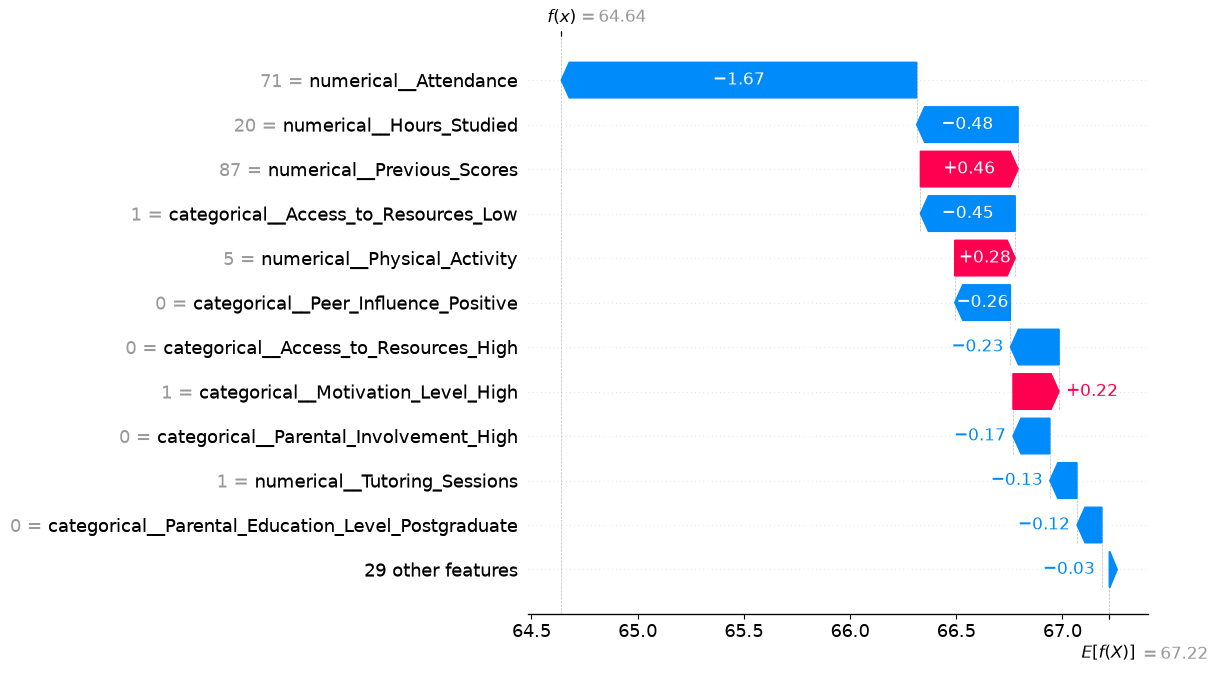

In [20]:
import numpy as np
import shap

base_value = np.asarray(explainer.expected_value).item()

feature_names = preprocessor.get_feature_names_out()

feature_values = (
    sample.toarray().flatten()
    if hasattr(sample, "toarray")
    else np.asarray(sample).flatten()
)

explanation = shap.Explanation(
    values=np.asarray(shap_values[0]).flatten(),
    base_values=base_value,
    data=feature_values,
    feature_names=feature_names
)

shap.plots.waterfall(explanation, max_display=12)

In [21]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_pred = model.predict(X_test_processed)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))
print("R2 Score:", round(r2, 4))

MAE: 1.0841
RMSE: 2.1657
R2 Score: 0.6682


In [22]:
import pandas as pd

evaluation_results = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2 Score"],
    "Value": [mae, rmse, r2]
})

evaluation_results.to_csv("model_evaluation_results.csv", index=False)

print("Evaluation results saved successfully!")
print(evaluation_results)

Evaluation results saved successfully!
     Metric     Value
0       MAE  1.084145
1      RMSE  2.165740
2  R2 Score  0.668171


In [23]:
feature_names = preprocessor.get_feature_names_out()

importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

importance.to_csv("feature_importance_results.csv", index=False)

print("Feature importance saved successfully!")
print(importance.head(10).to_string(index=False))

Feature importance saved successfully!
                               Feature  Importance
                 numerical__Attendance    0.375375
              numerical__Hours_Studied    0.239336
            numerical__Previous_Scores    0.083233
          numerical__Tutoring_Sessions    0.032399
          numerical__Physical_Activity    0.024904
                numerical__Sleep_Hours    0.024841
 categorical__Access_to_Resources_High    0.018933
categorical__Parental_Involvement_High    0.017589
 categorical__Parental_Involvement_Low    0.014610
       categorical__Family_Income_High    0.010834


In [24]:
shap_results = pd.DataFrame({
    "Feature": feature_names,
    "Feature_Value": feature_values,
    "SHAP_Contribution": np.asarray(shap_values[0]).flatten()
})

shap_results["Absolute_Contribution"] = (
    shap_results["SHAP_Contribution"].abs()
)

shap_results = shap_results.sort_values(
    by="Absolute_Contribution",
    ascending=False
)

shap_results.to_csv("shap_explanation_results.csv", index=False)

print("SHAP explanation saved successfully!")
print(shap_results.head(10).to_string(index=False))

SHAP explanation saved successfully!
                               Feature  Feature_Value  SHAP_Contribution  Absolute_Contribution
                 numerical__Attendance           71.0          -1.673261               1.673261
              numerical__Hours_Studied           20.0          -0.477937               0.477937
            numerical__Previous_Scores           87.0           0.460285               0.460285
  categorical__Access_to_Resources_Low            1.0          -0.446586               0.446586
          numerical__Physical_Activity            5.0           0.284924               0.284924
  categorical__Peer_Influence_Positive            0.0          -0.262531               0.262531
 categorical__Access_to_Resources_High            0.0          -0.229016               0.229016
    categorical__Motivation_Level_High            1.0           0.217205               0.217205
categorical__Parental_Involvement_High            0.0          -0.173436               0.173436
   

In [25]:
import joblib

joblib.dump(model, "student_performance_model.pkl")
joblib.dump(preprocessor, "student_preprocessor.pkl")

print("Model and preprocessor saved successfully!")

Model and preprocessor saved successfully!


In [26]:
from pathlib import Path
print(Path.cwd())

c:\Users\sahasrapathi\Desktop\explainable_ai_project\notebooks


In [1]:
import pandas as pd
import numpy as np
import joblib
from lime.lime_tabular import LimeTabularExplainer
from IPython.display import display

df = pd.read_csv("../data/raw/StudentPerformanceFactors.csv")

X = df.drop(columns=["Exam_Score"])
y = df["Exam_Score"]

model = joblib.load("student_performance_model.pkl")
preprocessor = joblib.load("student_preprocessor.pkl")

X_train = X.loc[X.index.isin(X.sample(frac=0.8, random_state=42).index)].copy()
X_test = X.drop(X_train.index).copy()

categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()
numerical_features = X.select_dtypes(exclude=["object", "category"]).columns.tolist()

X_train_processed = preprocessor.transform(X_train)

explainer = LimeTabularExplainer(
    training_data=np.asarray(X_train_processed),
    feature_names=preprocessor.get_feature_names_out().tolist(),
    mode="regression",
    random_state=42
)

student_index = 0
student = X_test.iloc[[student_index]]
student_processed = preprocessor.transform(student)

explanation = explainer.explain_instance(
    data_row=np.asarray(student_processed).ravel(),
    predict_fn=model.predict,
    num_features=10
)

print("Actual exam score:", y.loc[student.index[0]])
print("Predicted exam score:", model.predict(student_processed)[0])

display(pd.DataFrame(
    explanation.as_list(),
    columns=["Feature", "LIME Contribution"]
))

explanation.show_in_notebook(show_table=True)

C:\Users\sahasrapathi\AppData\Local\Temp\ipykernel_17012\655113017.py:18: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()


Actual exam score: 71
Predicted exam score: 71.21


,Feature,LIME Contribution
0,numerical__Hours_Studied > 24.00,3.189032
1,80.00 < numerical__Attendance <= 90.00,1.431340
2,numerical__Previous_Scores > 87.00,1.220530
3,categorical__Access_to_Resources_High <= 0.00,-0.685503
4,categorical__Parental_Involvement_High <= 0.00,-0.633819
5,numerical__Tutoring_Sessions <= 1.00,-0.621543
6,categorical__Parental_Education_Level_Postgrad...,-0.491288
7,categorical__Access_to_Resources_Low <= 0.00,0.465524
8,categorical__Parental_Involvement_Low > 0.00,-0.379688
9,categorical__Learning_Disabilities_Yes <= 0.00,0.317866


ImportError: cannot import name 'display' from 'IPython.core.display' (c:\Users\sahasrapathi\Desktop\explainable_ai_project\venv\Lib\site-packages\IPython\core\display.py)

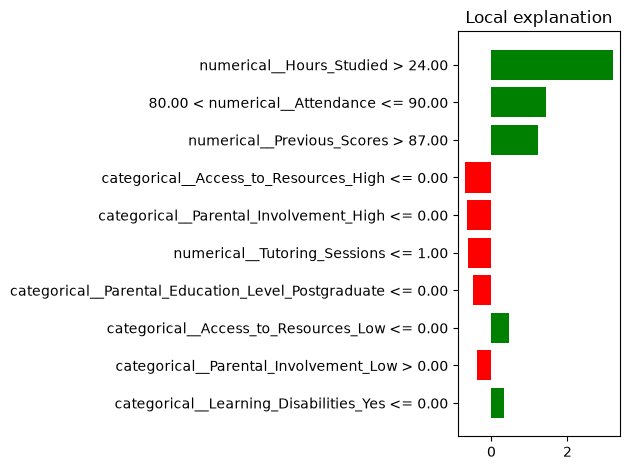

In [2]:
import matplotlib.pyplot as plt

fig = explanation.as_pyplot_figure()
plt.tight_layout()
plt.show()

In [3]:
lime_results = pd.DataFrame(
    explanation.as_list(),
    columns=["Feature", "LIME_Contribution"]
)

lime_results.to_csv("lime_explanation_results.csv", index=False)

fig = explanation.as_pyplot_figure()
fig.savefig("lime_explanation_plot.png", dpi=300, bbox_inches="tight")
plt.close(fig)

print("LIME results and plot saved successfully.")

LIME results and plot saved successfully.


In [4]:
student_index = 0
student = X_test.iloc[[student_index]]

student_processed = preprocessor.transform(student)

print("Student index:", student.index[0])
print("Actual exam score:", y.loc[student.index[0]])
print("Predicted exam score:", model.predict(student_processed)[0])

Student index: 3
Actual exam score: 71
Predicted exam score: 71.21


In [5]:
import shap
import pandas as pd
import numpy as np

student_index = 0
student = X_test.iloc[[student_index]]
student_processed = preprocessor.transform(student)

feature_names = preprocessor.get_feature_names_out()

shap_explainer = shap.TreeExplainer(model)
shap_values = shap_explainer.shap_values(student_processed)

shap_comparison = pd.DataFrame({
    "Feature": feature_names,
    "SHAP_Contribution": np.asarray(shap_values).reshape(-1)
})

shap_comparison["Absolute_SHAP"] = shap_comparison["SHAP_Contribution"].abs()
shap_comparison = shap_comparison.sort_values(
    "Absolute_SHAP", ascending=False
)

display(shap_comparison.head(10))

c:\Users\sahasrapathi\Desktop\explainable_ai_project\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,Feature,SHAP_Contribution,Absolute_SHAP
0,numerical__Hours_Studied,2.459666,2.459666
1,numerical__Attendance,1.613534,1.613534
3,numerical__Previous_Scores,1.103311,1.103311
7,categorical__Parental_Involvement_Low,-0.271743,0.271743
4,numerical__Tutoring_Sessions,-0.219377,0.219377
6,categorical__Parental_Involvement_High,-0.187966,0.187966
9,categorical__Access_to_Resources_High,-0.178411,0.178411
27,categorical__Peer_Influence_Negative,-0.088569,0.088569
37,categorical__Distance_from_Home_Near,-0.087141,0.087141
33,categorical__Parental_Education_Level_High School,-0.078341,0.078341


In [6]:
lime_comparison = pd.DataFrame(
    explanation.as_list(),
    columns=["Feature", "LIME_Contribution"]
)

comparison = shap_comparison.merge(
    lime_comparison,
    on="Feature",
    how="outer"
)

comparison["Absolute_SHAP"] = comparison["SHAP_Contribution"].abs()
comparison["Absolute_LIME"] = comparison["LIME_Contribution"].abs()

comparison = comparison.sort_values(
    "Absolute_SHAP", ascending=False
)

display(
    comparison[
        ["Feature", "SHAP_Contribution", "LIME_Contribution"]
    ].head(15).round(4)
)

,Feature,SHAP_Contribution,LIME_Contribution
42,numerical__Hours_Studied,2.4597,NaN
41,numerical__Attendance,1.6135,NaN
45,numerical__Previous_Scores,1.1033,NaN
30,categorical__Parental_Involvement_Low,-0.2717,NaN
48,numerical__Tutoring_Sessions,-0.2194,NaN
28,categorical__Parental_Involvement_High,-0.1880,NaN
1,categorical__Access_to_Resources_High,-0.1784,NaN
33,categorical__Peer_Influence_Negative,-0.0886,NaN
8,categorical__Distance_from_Home_Near,-0.0871,NaN
25,categorical__Parental_Education_Level_High School,-0.0783,NaN


In [7]:
import re
import pandas as pd

lime_comparison = pd.DataFrame(
    explanation.as_list(),
    columns=["LIME_Feature_Condition", "LIME_Contribution"]
)

lime_comparison["Feature"] = lime_comparison["LIME_Feature_Condition"].apply(
    lambda x: re.sub(r"^(.*?)\s*(?:<=|>=|<|>|=).*?$", r"\1", x).strip()
)

comparison = shap_comparison.merge(
    lime_comparison[["Feature", "LIME_Feature_Condition", "LIME_Contribution"]],
    on="Feature",
    how="left"
)

display(
    comparison[
        ["Feature", "SHAP_Contribution", "LIME_Contribution", "LIME_Feature_Condition"]
    ].head(15).round(4)
)

,Feature,SHAP_Contribution,LIME_Contribution,LIME_Feature_Condition
0,numerical__Hours_Studied,2.4597,3.1890,numerical__Hours_Studied > 24.00
1,numerical__Attendance,1.6135,NaN,NaN
2,numerical__Previous_Scores,1.1033,1.2205,numerical__Previous_Scores > 87.00
3,categorical__Parental_Involvement_Low,-0.2717,-0.3797,categorical__Parental_Involvement_Low > 0.00
4,numerical__Tutoring_Sessions,-0.2194,-0.6215,numerical__Tutoring_Sessions <= 1.00
5,categorical__Parental_Involvement_High,-0.1880,-0.6338,categorical__Parental_Involvement_High <= 0.00
6,categorical__Access_to_Resources_High,-0.1784,-0.6855,categorical__Access_to_Resources_High <= 0.00
7,categorical__Peer_Influence_Negative,-0.0886,NaN,NaN
8,categorical__Distance_from_Home_Near,-0.0871,NaN,NaN
9,categorical__Parental_Education_Level_High School,-0.0783,NaN,NaN


In [8]:
comparison_clean = comparison.dropna(
    subset=["SHAP_Contribution", "LIME_Contribution"]
).copy()

comparison_clean["SHAP_Direction"] = np.where(
    comparison_clean["SHAP_Contribution"] > 0, "Positive",
    np.where(comparison_clean["SHAP_Contribution"] < 0, "Negative", "Zero")
)

comparison_clean["LIME_Direction"] = np.where(
    comparison_clean["LIME_Contribution"] > 0, "Positive",
    np.where(comparison_clean["LIME_Contribution"] < 0, "Negative", "Zero")
)

comparison_clean["Direction_Agrees"] = (
    comparison_clean["SHAP_Direction"] == comparison_clean["LIME_Direction"]
)

display(
    comparison_clean[
        [
            "Feature",
            "SHAP_Contribution",
            "LIME_Contribution",
            "SHAP_Direction",
            "LIME_Direction",
            "Direction_Agrees"
        ]
    ].round(4)
)

print("Features compared:", len(comparison_clean))
print(
    "Direction agreement:",
    round(comparison_clean["Direction_Agrees"].mean() * 100, 2),
    "%"
)

,Feature,SHAP_Contribution,LIME_Contribution,SHAP_Direction,LIME_Direction,Direction_Agrees
0,numerical__Hours_Studied,2.4597,3.1890,Positive,Positive,True
2,numerical__Previous_Scores,1.1033,1.2205,Positive,Positive,True
3,categorical__Parental_Involvement_Low,-0.2717,-0.3797,Negative,Negative,True
4,numerical__Tutoring_Sessions,-0.2194,-0.6215,Negative,Negative,True
5,categorical__Parental_Involvement_High,-0.1880,-0.6338,Negative,Negative,True
6,categorical__Access_to_Resources_High,-0.1784,-0.6855,Negative,Negative,True
11,categorical__Parental_Education_Level_Postgrad...,-0.0661,-0.4913,Negative,Negative,True
12,categorical__Access_to_Resources_Low,0.0619,0.4655,Positive,Positive,True
32,categorical__Learning_Disabilities_Yes,0.0061,0.3179,Positive,Positive,True


Features compared: 9
Direction agreement: 100.0 %


In [9]:
comparison_clean.to_csv(
    "shap_lime_comparison_results.csv",
    index=False
)

agreement_percentage = (
    comparison_clean["Direction_Agrees"].mean() * 100
)

summary = pd.DataFrame({
    "Metric": [
        "Student index",
        "Actual exam score",
        "Predicted exam score",
        "Number of matched features",
        "Direction agreement (%)"
    ],
    "Value": [
        int(student.index[0]),
        float(y.loc[student.index[0]]),
        float(model.predict(student_processed)[0]),
        len(comparison_clean),
        round(agreement_percentage, 2)
    ]
})

summary.to_csv("shap_lime_comparison_summary.csv", index=False)

display(summary)
print("Comparison files saved successfully.")

,Metric,Value
0,Student index,3.00
1,Actual exam score,71.00
2,Predicted exam score,71.21
3,Number of matched features,9.00
4,Direction agreement (%),100.00


Comparison files saved successfully.


In [10]:
print("Test dataset shape:", X_test.shape)
print("Number of test students:", len(X_test))
print("Model loaded:", model is not None)
print("Preprocessor loaded:", preprocessor is not None)
print("SHAP comparison available:", "shap_comparison" in globals())
print("LIME explanation available:", "explanation" in globals())

Test dataset shape: (1321, 19)
Number of test students: 1321
Model loaded: True
Preprocessor loaded: True
SHAP comparison available: True
LIME explanation available: True


In [11]:
sample_size = 30

X_explain = X_test.sample(
    n=sample_size,
    random_state=42
).copy()

print("Students selected for explanation:", len(X_explain))
print("Unique student rows:", X_explain.index.nunique())
print("Feature count:", X_explain.shape[1])

Students selected for explanation: 30
Unique student rows: 30
Feature count: 19


In [12]:
import numpy as np
import pandas as pd
import shap

X_explain_processed = preprocessor.transform(X_explain)

shap_explainer = shap.TreeExplainer(model)

shap_values_30 = shap_explainer.shap_values(
    X_explain_processed
)

shap_values_30 = np.asarray(shap_values_30)

print("SHAP explanations generated successfully.")
print("SHAP matrix shape:", shap_values_30.shape)
print("Students explained:", shap_values_30.shape[0])
print("Features explained:", shap_values_30.shape[1])

SHAP explanations generated successfully.
SHAP matrix shape: (30, 40)
Students explained: 30
Features explained: 40


In [13]:
from lime.lime_tabular import LimeTabularExplainer
import numpy as np
import pandas as pd

feature_names = preprocessor.get_feature_names_out().tolist()

lime_explainer = LimeTabularExplainer(
    training_data=np.asarray(X_train_processed),
    feature_names=feature_names,
    mode="regression",
    random_state=42
)

lime_results_30 = []

for student_id in range(len(X_explain)):
    student_row = X_explain_processed[student_id]

    lime_exp = lime_explainer.explain_instance(
        data_row=np.asarray(student_row).ravel(),
        predict_fn=model.predict,
        num_features=10,
        num_samples=3000
    )

    for feature_condition, contribution in lime_exp.as_list():
        lime_results_30.append({
            "Student_Index": X_explain.index[student_id],
            "Feature_Condition": feature_condition,
            "LIME_Contribution": contribution
        })

lime_results_30 = pd.DataFrame(lime_results_30)

print("LIME explanations generated successfully.")
print("Students explained:", lime_results_30["Student_Index"].nunique())
print("Total LIME explanation rows:", len(lime_results_30))

display(lime_results_30.head(10))

LIME explanations generated successfully.
Students explained: 30
Total LIME explanation rows: 300


,Student_Index,Feature_Condition,LIME_Contribution
0,3696,80.00 < numerical__Attendance <= 90.00,1.230752
1,3696,categorical__Access_to_Resources_High <= 0.00,-0.758849
2,3696,categorical__Parental_Involvement_High <= 0.00,-0.698863
3,3696,numerical__Tutoring_Sessions <= 1.00,-0.582933
4,3696,16.00 < numerical__Hours_Studied <= 20.00,-0.495643
5,3696,63.00 < numerical__Previous_Scores <= 75.00,-0.445656
6,3696,categorical__Parental_Involvement_Low <= 0.00,0.412551
7,3696,categorical__Access_to_Resources_Low <= 0.00,0.399797
8,3696,categorical__Learning_Disabilities_Yes <= 0.00,0.325023
9,3696,0.00 < categorical__Access_to_Resources_Medium...,0.277569


In [14]:
import re
import numpy as np
import pandas as pd

lime_results_30["Feature"] = lime_results_30[
    "Feature_Condition"
].apply(
    lambda x: re.sub(
        r"^(.*?)\s*(?:<=|>=|<|>|=).*?$",
        r"\1",
        x
    ).strip()
)

shap_rows = []

feature_names = preprocessor.get_feature_names_out().tolist()

for i, student_index in enumerate(X_explain.index):
    for j, feature in enumerate(feature_names):
        shap_rows.append({
            "Student_Index": student_index,
            "Feature": feature,
            "SHAP_Contribution": shap_values_30[i, j]
        })

shap_results_30 = pd.DataFrame(shap_rows)

matched_results = shap_results_30.merge(
    lime_results_30,
    on=["Student_Index", "Feature"],
    how="inner"
)

matched_results["SHAP_Direction"] = np.sign(
    matched_results["SHAP_Contribution"]
)

matched_results["LIME_Direction"] = np.sign(
    matched_results["LIME_Contribution"]
)

matched_results["Direction_Agrees"] = (
    matched_results["SHAP_Direction"]
    == matched_results["LIME_Direction"]
)

print("Students compared:", matched_results["Student_Index"].nunique())
print("Matched feature explanations:", len(matched_results))

if len(matched_results) > 0:
    print(
        "Overall direction agreement (%):",
        round(matched_results["Direction_Agrees"].mean() * 100, 2)
    )

    display(matched_results.head(15))
else:
    print("No features matched. We will inspect LIME feature names.")

Students compared: 30
Matched feature explanations: 238
Overall direction agreement (%): 95.8


,Student_Index,Feature,SHAP_Contribution,Feature_Condition,LIME_Contribution,SHAP_Direction,LIME_Direction,Direction_Agrees
0,3696,numerical__Tutoring_Sessions,-0.217670,numerical__Tutoring_Sessions <= 1.00,-0.582933,-1.0,-1.0,True
1,3696,categorical__Parental_Involvement_High,-0.183936,categorical__Parental_Involvement_High <= 0.00,-0.698863,-1.0,-1.0,True
2,3696,categorical__Parental_Involvement_Low,0.129441,categorical__Parental_Involvement_Low <= 0.00,0.412551,1.0,1.0,True
3,3696,categorical__Access_to_Resources_High,-0.249846,categorical__Access_to_Resources_High <= 0.00,-0.758849,-1.0,-1.0,True
4,3696,categorical__Access_to_Resources_Low,0.097896,categorical__Access_to_Resources_Low <= 0.00,0.399797,1.0,1.0,True
5,3696,categorical__Learning_Disabilities_Yes,0.022748,categorical__Learning_Disabilities_Yes <= 0.00,0.325023,1.0,1.0,True
6,2595,numerical__Hours_Studied,1.296115,numerical__Hours_Studied <= 16.00,-3.029493,1.0,-1.0,False
7,2595,numerical__Attendance,1.650062,numerical__Attendance <= 70.00,-4.063993,1.0,-1.0,False
8,2595,numerical__Previous_Scores,0.500414,numerical__Previous_Scores <= 63.00,-0.840578,1.0,-1.0,False
9,2595,numerical__Tutoring_Sessions,-0.112642,numerical__Tutoring_Sessions <= 1.00,-0.768088,-1.0,-1.0,True


In [15]:
agreement_by_student = (
    matched_results
    .groupby("Student_Index")
    .agg(
        Matched_Features=("Feature", "count"),
        Direction_Agreement=("Direction_Agrees", "mean")
    )
    .reset_index()
)

agreement_by_student["Direction_Agreement_Percent"] = (
    agreement_by_student["Direction_Agreement"] * 100
)

overall_agreement = matched_results["Direction_Agrees"].mean() * 100

print("Students with matched explanations:",
      agreement_by_student["Student_Index"].nunique())

print("Total matched feature explanations:",
      len(matched_results))

print("Overall direction agreement (%):",
      round(overall_agreement, 2))

print("\nAgreement by student:")
display(agreement_by_student.round(2))

matched_results.to_csv(
    "shap_lime_multi_student_matched_results.csv",
    index=False
)

agreement_by_student.to_csv(
    "shap_lime_agreement_by_student.csv",
    index=False
)

print("\nComparison results saved successfully.")

Students with matched explanations: 30
Total matched feature explanations: 238
Overall direction agreement (%): 95.8

Agreement by student:


,Student_Index,Matched_Features,Direction_Agreement,Direction_Agreement_Percent
0,285,9,1.00,100.00
1,302,7,1.00,100.00
2,384,9,1.00,100.00
3,608,9,1.00,100.00
4,1318,6,0.83,83.33
5,1396,10,0.90,90.00
6,1639,8,0.88,87.50
7,1646,9,1.00,100.00
8,1761,7,1.00,100.00
9,1955,8,1.00,100.00



Comparison results saved successfully.


In [16]:
print("SHAP rows:", len(shap_results_30))
print("LIME rows:", len(lime_results_30))
print("Matched rows:", len(matched_results))

print("\nDuplicate SHAP student-feature pairs:",
      shap_results_30.duplicated(
          subset=["Student_Index", "Feature"]
      ).sum())

print("Duplicate LIME student-feature pairs:",
      lime_results_30.duplicated(
          subset=["Student_Index", "Feature"]
      ).sum())

SHAP rows: 1200
LIME rows: 300
Matched rows: 238

Duplicate SHAP student-feature pairs: 0
Duplicate LIME student-feature pairs: 6


In [19]:
lime_results_30 = []

feature_names = preprocessor.get_feature_names_out().tolist()

for student_id in range(len(X_explain)):
    student_row = X_explain_processed[student_id]

    lime_exp = lime_explainer.explain_instance(
        data_row=np.asarray(student_row).ravel(),
        predict_fn=model.predict,
        num_features=10,
        num_samples=3000
    )

    for feature_id, contribution in lime_exp.local_exp[1]:
        lime_results_30.append({
            "Student_Index": X_explain.index[student_id],
            "Feature": feature_names[feature_id],
            "LIME_Contribution": contribution
        })

lime_results_30 = pd.DataFrame(lime_results_30)

print("LIME rows:", len(lime_results_30))
print(
    "Duplicate student-feature pairs:",
    lime_results_30.duplicated(
        subset=["Student_Index", "Feature"]
    ).sum()
)

print(lime_results_30.head(10))

LIME rows: 300
Duplicate student-feature pairs: 0
   Student_Index                                 Feature  LIME_Contribution
0           3696                   numerical__Attendance           1.204423
1           3696                numerical__Hours_Studied          -0.760337
2           3696  categorical__Parental_Involvement_High          -0.703043
3           3696   categorical__Parental_Involvement_Low           0.563309
4           3696              numerical__Previous_Scores          -0.531507
5           3696   categorical__Access_to_Resources_High          -0.497773
6           3696            numerical__Tutoring_Sessions          -0.485592
7           3696     categorical__Distance_from_Home_Far          -0.423362
8           3696       categorical__Teacher_Quality_High          -0.319640
9           3696         categorical__Family_Income_High          -0.300687


In [20]:
shap_rows = []

feature_names = preprocessor.get_feature_names_out().tolist()

for i, student_index in enumerate(X_explain.index):
    for j, feature in enumerate(feature_names):
        shap_rows.append({
            "Student_Index": student_index,
            "Feature": feature,
            "SHAP_Contribution": shap_values_30[i, j]
        })

shap_results_30 = pd.DataFrame(shap_rows)

matched_results = shap_results_30.merge(
    lime_results_30,
    on=["Student_Index", "Feature"],
    how="inner"
)

matched_results["SHAP_Direction"] = np.sign(
    matched_results["SHAP_Contribution"]
)

matched_results["LIME_Direction"] = np.sign(
    matched_results["LIME_Contribution"]
)

matched_results["Direction_Agrees"] = (
    matched_results["SHAP_Direction"]
    == matched_results["LIME_Direction"]
)

agreement_by_student = (
    matched_results.groupby("Student_Index")
    .agg(
        Matched_Features=("Feature", "count"),
        Direction_Agreement=("Direction_Agrees", "mean")
    )
    .reset_index()
)

agreement_by_student["Direction_Agreement_Percent"] = (
    agreement_by_student["Direction_Agreement"] * 100
)

overall_agreement = (
    matched_results["Direction_Agrees"].mean() * 100
)

print("SHAP rows:", len(shap_results_30))
print("LIME rows:", len(lime_results_30))
print("Matched rows:", len(matched_results))
print("Overall direction agreement:", round(overall_agreement, 2), "%")

print("\nAgreement by student:")
print(agreement_by_student.head(10).to_string(index=False))

SHAP rows: 1200
LIME rows: 300
Matched rows: 300
Overall direction agreement: 96.0 %

Agreement by student:
 Student_Index  Matched_Features  Direction_Agreement  Direction_Agreement_Percent
           285                10                  1.0                        100.0
           302                10                  0.9                         90.0
           384                10                  1.0                        100.0
           608                10                  1.0                        100.0
          1318                10                  1.0                        100.0
          1396                10                  1.0                        100.0
          1639                10                  0.9                         90.0
          1646                10                  0.9                         90.0
          1761                10                  0.9                         90.0
          1955                10                  0.9         

In [22]:
matched_results.to_csv(
    "shap_lime_matched_results_30_students.csv",
    index=False
)

agreement_by_student.to_csv(
    "shap_lime_agreement_by_student.csv",
    index=False
)

overall_summary = pd.DataFrame([{
    "Students_Analyzed": len(X_explain),
    "SHAP_Rows": len(shap_results_30),
    "LIME_Rows": len(lime_results_30),
    "Matched_Features": len(matched_results),
    "Direction_Agreement_Percent": overall_agreement
}])

overall_summary.to_csv(
    "shap_lime_overall_summary.csv",
    index=False
)

print("SHAP-LIME comparison files saved successfully.")
print(overall_summary.to_string(index=False))

SHAP-LIME comparison files saved successfully.
 Students_Analyzed  SHAP_Rows  LIME_Rows  Matched_Features  Direction_Agreement_Percent
                30       1200        300               300                         96.0


In [1]:
print("Dataset shape:", X.shape)
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

print("Training and testing indices overlap:",
      len(set(X_train.index) & set(X_test.index)))

NameError: name 'X' is not defined

In [2]:
import pandas as pd

df = pd.read_csv("../data/raw/StudentPerformanceFactors.csv")

X = df.drop(columns=["Exam_Score"])
y = df["Exam_Score"]

print("Dataset shape:", df.shape)
print("X shape:", X.shape)
print("y shape:", y.shape)

Dataset shape: (6607, 20)
X shape: (6607, 19)
y shape: (6607,)


In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

print(
    "Overlapping indices:",
    len(set(X_train.index) & set(X_test.index))
)

Training features: (5285, 19)
Testing features: (1322, 19)
Training target: (5285,)
Testing target: (1322,)
Overlapping indices: 0


In [4]:
import joblib

model = joblib.load("student_performance_model.pkl")
preprocessor = joblib.load("student_preprocessor.pkl")

print("Model loaded:", type(model).__name__)
print("Preprocessor loaded:", type(preprocessor).__name__)
print("Model expects features:", model.n_features_in_)
print("Preprocessor expects input columns:", len(preprocessor.feature_names_in_))

Model loaded: RandomForestRegressor
Preprocessor loaded: ColumnTransformer
Model expects features: 40
Preprocessor expects input columns: 19


In [5]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X_test_processed = preprocessor.transform(X_test)

y_pred = model.predict(X_test_processed)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("FINAL MODEL EVALUATION")
print("----------------------")
print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))
print("R2 Score:", round(r2, 4))
print("Test samples:", len(y_test))
print("Predictions generated:", len(y_pred))

FINAL MODEL EVALUATION
----------------------
MAE: 1.0841
RMSE: 2.1657
R2 Score: 0.6682
Test samples: 1322
Predictions generated: 1322


In [6]:
student = pd.DataFrame([{
    "Hours_Studied": 2,
    "Attendance": 65,
    "Parental_Involvement": "Low",
    "Access_to_Resources": "Low",
    "Extracurricular_Activities": "No",
    "Sleep_Hours": 6,
    "Previous_Scores": 55,
    "Motivation_Level": "Low",
    "Internet_Access": "Yes",
    "Tutoring_Sessions": 0,
    "Family_Income": "Low",
    "Teacher_Quality": "Medium",
    "School_Type": "Public",
    "Peer_Influence": "Negative",
    "Physical_Activity": 2,
    "Learning_Disabilities": "No",
    "Parental_Education_Level": "High School",
    "Distance_from_Home": "Near",
    "Gender": "Female"
}])

student_processed = preprocessor.transform(student)
predicted_score = model.predict(student_processed)[0]

print("Predicted Exam Score:", round(predicted_score, 2))

Predicted Exam Score: 57.68


c:\Users\sahasrapathi\Desktop\explainable_ai_project\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Predicted Exam Score: 57.68

Top 10 SHAP Contributions:
                               Feature  SHAP_Contribution
                 numerical__Attendance          -3.646630
              numerical__Hours_Studied          -3.429880
            numerical__Previous_Scores          -0.605124
          numerical__Tutoring_Sessions          -0.317476
categorical__Parental_Involvement_High          -0.289697
  categorical__Access_to_Resources_Low          -0.197025
 categorical__Parental_Involvement_Low          -0.163788
          numerical__Physical_Activity          -0.152129
 categorical__Access_to_Resources_High          -0.131799
    categorical__Motivation_Level_High          -0.129518


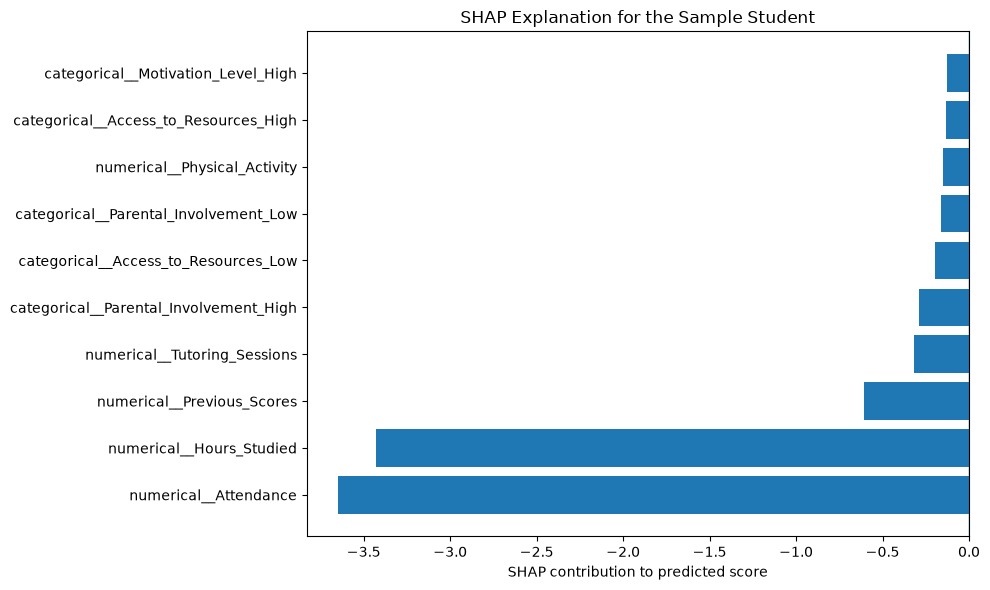

In [7]:
import shap
import matplotlib.pyplot as plt
import pandas as pd

feature_names = preprocessor.get_feature_names_out().tolist()

student_processed_df = pd.DataFrame(
    student_processed,
    columns=feature_names
)

shap_explainer = shap.TreeExplainer(model)

shap_values_student = shap_explainer.shap_values(
    student_processed
)

shap_values_one = shap_values_student[0]

shap_importance = pd.DataFrame({
    "Feature": feature_names,
    "SHAP_Contribution": shap_values_one
})

shap_importance["Absolute_Contribution"] = (
    shap_importance["SHAP_Contribution"].abs()
)

shap_importance = shap_importance.sort_values(
    "Absolute_Contribution",
    ascending=False
)

print("Predicted Exam Score:", round(predicted_score, 2))
print("\nTop 10 SHAP Contributions:")
print(
    shap_importance[
        ["Feature", "SHAP_Contribution"]
    ].head(10).to_string(index=False)
)

top_features = shap_importance.head(10).sort_values(
    "SHAP_Contribution"
)

plt.figure(figsize=(10, 6))
plt.barh(
    top_features["Feature"],
    top_features["SHAP_Contribution"]
)
plt.axvline(0, linewidth=1)
plt.xlabel("SHAP contribution to predicted score")
plt.title("SHAP Explanation for the Sample Student")
plt.tight_layout()
plt.show()

Predicted Exam Score: 57.68

LIME Explanation:
numerical__Attendance <= 70.00: -3.9659
numerical__Hours_Studied <= 16.00: -3.2363
numerical__Previous_Scores <= 63.00: -1.0186
categorical__Access_to_Resources_High <= 0.00: -0.7930
categorical__Parental_Involvement_High <= 0.00: -0.6489
numerical__Tutoring_Sessions <= 1.00: -0.5445
categorical__Parental_Involvement_Low > 0.00: -0.3618
categorical__Access_to_Resources_Low > 0.00: -0.3307
0.00 < categorical__Family_Income_Low <= 1.00: -0.2746
categorical__Peer_Influence_Positive <= 0.00: -0.2331


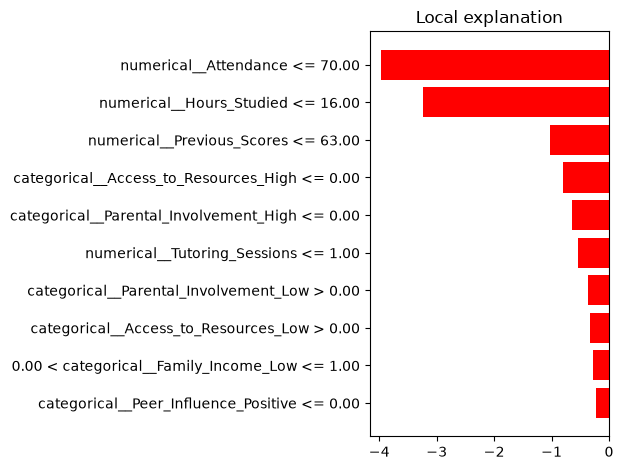

In [8]:
from lime.lime_tabular import LimeTabularExplainer
import numpy as np
import matplotlib.pyplot as plt

X_train_processed = preprocessor.transform(X_train)

feature_names = preprocessor.get_feature_names_out().tolist()

lime_explainer = LimeTabularExplainer(
    training_data=np.asarray(X_train_processed),
    feature_names=feature_names,
    mode="regression",
    random_state=42
)

lime_exp_student = lime_explainer.explain_instance(
    data_row=np.asarray(student_processed).ravel(),
    predict_fn=model.predict,
    num_features=10,
    num_samples=3000
)

print("Predicted Exam Score:", round(predicted_score, 2))
print("\nLIME Explanation:")

for feature, contribution in lime_exp_student.as_list():
    print(f"{feature}: {contribution:.4f}")

fig = lime_exp_student.as_pyplot_figure()
plt.tight_layout()
plt.show()

In [9]:
print("Exam Score Statistics")
print(y.describe().round(2))

print("\nScore Distribution:")
print("Below 60:", (y < 60).sum())
print("60 to below 75:", ((y >= 60) & (y < 75)).sum())
print("75 and above:", (y >= 75).sum())

Exam Score Statistics
count    6607.00
mean       67.24
std         3.89
min        55.00
25%        65.00
50%        67.00
75%        69.00
max       101.00
Name: Exam_Score, dtype: float64

Score Distribution:
Below 60: 68
60 to below 75: 6415
75 and above: 124


In [10]:
print("Scores above 100:", (y > 100).sum())
print("Scores below 0:", (y < 0).sum())

print("\nProvisional score categories:")
print("High risk (below 60):", (y < 60).sum())
print(
    "Moderate risk (60 to below 65):",
    ((y >= 60) & (y < 65)).sum()
)
print("Lower predicted risk (65 and above):", (y >= 65).sum())

Scores above 100: 1
Scores below 0: 0

Provisional score categories:
High risk (below 60): 68
Moderate risk (60 to below 65): 1384
Lower predicted risk (65 and above): 5155


In [11]:
def classify_academic_risk(score):
    if score < 60:
        return "High Risk"
    elif score < 65:
        return "Moderate Risk"
    else:
        return "Lower Predicted Risk"


risk_category = classify_academic_risk(predicted_score)

print("Predicted Exam Score:", round(predicted_score, 2))
print("Academic Risk Category:", risk_category)

Predicted Exam Score: 57.68
Academic Risk Category: High Risk


In [12]:
def generate_interventions(student, risk_category):
    interventions = []

    if student["Attendance"].iloc[0] < 75:
        interventions.append(
            "Attendance is low. Identify barriers to attendance "
            "and create a plan for regular class participation."
        )

    if student["Hours_Studied"].iloc[0] < 3:
        interventions.append(
            "Consider a consistent daily study schedule with "
            "short, focused study sessions."
        )

    if student["Previous_Scores"].iloc[0] < 60:
        interventions.append(
            "Review previous assessments to identify topics "
            "that need additional practice."
        )

    if student["Tutoring_Sessions"].iloc[0] < 2:
        interventions.append(
            "Consider extra academic support, peer learning, "
            "or tutoring where available."
        )

    if student["Sleep_Hours"].iloc[0] < 7:
        interventions.append(
            "Review sleep habits and aim for a regular, "
            "adequate sleep schedule."
        )

    if student["Access_to_Resources"].iloc[0] == "Low":
        interventions.append(
            "Check whether the student needs access to study "
            "materials, a quiet study space, or internet resources."
        )

    if risk_category == "High Risk":
        interventions.append(
            "Arrange a supportive check-in with a teacher or "
            "academic advisor and monitor progress regularly."
        )

    return interventions


interventions = generate_interventions(student, risk_category)

print("ACADEMIC INTERVENTION SUGGESTIONS")
print("--------------------------------")

for i, suggestion in enumerate(interventions, start=1):
    print(f"{i}. {suggestion}")

ACADEMIC INTERVENTION SUGGESTIONS
--------------------------------
1. Attendance is low. Identify barriers to attendance and create a plan for regular class participation.
2. Consider a consistent daily study schedule with short, focused study sessions.
3. Review previous assessments to identify topics that need additional practice.
4. Consider extra academic support, peer learning, or tutoring where available.
5. Review sleep habits and aim for a regular, adequate sleep schedule.
6. Check whether the student needs access to study materials, a quiet study space, or internet resources.
7. Arrange a supportive check-in with a teacher or academic advisor and monitor progress regularly.


In [13]:
print("=" * 55)
print("STUDENT ACADEMIC PERFORMANCE REPORT")
print("=" * 55)

print("\n1. PREDICTION")
print("Predicted Exam Score:", round(predicted_score, 2), "/ 100")

print("\n2. ACADEMIC RISK")
print("Risk Category:", risk_category)
print("Note: Risk thresholds are provisional and require validation.")

print("\n3. TOP SHAP EXPLANATIONS")
for _, row in shap_importance.head(5).iterrows():
    direction = "increases" if row["SHAP_Contribution"] > 0 else "decreases"
    print(
        f'{row["Feature"]}: {direction} the prediction '
        f'({row["SHAP_Contribution"]:.3f})'
    )

print("\n4. TOP LIME EXPLANATIONS")
for feature, contribution in lime_exp_student.as_list()[:5]:
    direction = "increases" if contribution > 0 else "decreases"
    print(f"{feature}: {direction} the local prediction ({contribution:.3f})")

print("\n5. SUGGESTED INTERVENTIONS")
for i, suggestion in enumerate(interventions, start=1):
    print(f"{i}. {suggestion}")

print("\n" + "=" * 55)
print("END OF REPORT")
print("=" * 55)

STUDENT ACADEMIC PERFORMANCE REPORT

1. PREDICTION
Predicted Exam Score: 57.68 / 100

2. ACADEMIC RISK
Risk Category: High Risk
Note: Risk thresholds are provisional and require validation.

3. TOP SHAP EXPLANATIONS
numerical__Attendance: decreases the prediction (-3.647)
numerical__Hours_Studied: decreases the prediction (-3.430)
numerical__Previous_Scores: decreases the prediction (-0.605)
numerical__Tutoring_Sessions: decreases the prediction (-0.317)
categorical__Parental_Involvement_High: decreases the prediction (-0.290)

4. TOP LIME EXPLANATIONS
numerical__Attendance <= 70.00: decreases the local prediction (-3.966)
numerical__Hours_Studied <= 16.00: decreases the local prediction (-3.236)
numerical__Previous_Scores <= 63.00: decreases the local prediction (-1.019)
categorical__Access_to_Resources_High <= 0.00: decreases the local prediction (-0.793)
categorical__Parental_Involvement_High <= 0.00: decreases the local prediction (-0.649)

5. SUGGESTED INTERVENTIONS
1. Attendance 

In [14]:
from IPython.display import display, Markdown

report = []

report.append("# Student Academic Performance Report")
report.append(f"**Predicted Exam Score:** {predicted_score:.2f} / 100")
report.append(f"**Academic Risk:** {risk_category}")
report.append(
    "**Note:** Risk categories use provisional thresholds "
    "that require validation."
)

report.append("\n## Top SHAP Explanations")
for _, row in shap_importance.head(5).iterrows():
    contribution = row["SHAP_Contribution"]
    direction = "increases" if contribution > 0 else "decreases"
    report.append(
        f"- **{row['Feature']}**: {direction} the prediction "
        f"({contribution:.3f})"
    )

report.append("\n## Top LIME Explanations")
for feature, contribution in lime_exp_student.as_list()[:5]:
    direction = "increases" if contribution > 0 else "decreases"
    report.append(
        f"- **{feature}**: {direction} the local prediction "
        f"({contribution:.3f})"
    )

report.append("\n## Suggested Interventions")
for i, suggestion in enumerate(interventions, start=1):
    report.append(f"{i}. {suggestion}")

display(Markdown("\n\n".join(report)))

# Student Academic Performance Report

**Predicted Exam Score:** 57.68 / 100

**Academic Risk:** High Risk

**Note:** Risk categories use provisional thresholds that require validation.


## Top SHAP Explanations

- **numerical__Attendance**: decreases the prediction (-3.647)

- **numerical__Hours_Studied**: decreases the prediction (-3.430)

- **numerical__Previous_Scores**: decreases the prediction (-0.605)

- **numerical__Tutoring_Sessions**: decreases the prediction (-0.317)

- **categorical__Parental_Involvement_High**: decreases the prediction (-0.290)


## Top LIME Explanations

- **numerical__Attendance <= 70.00**: decreases the local prediction (-3.966)

- **numerical__Hours_Studied <= 16.00**: decreases the local prediction (-3.236)

- **numerical__Previous_Scores <= 63.00**: decreases the local prediction (-1.019)

- **categorical__Access_to_Resources_High <= 0.00**: decreases the local prediction (-0.793)

- **categorical__Parental_Involvement_High <= 0.00**: decreases the local prediction (-0.649)


## Suggested Interventions

1. Attendance is low. Identify barriers to attendance and create a plan for regular class participation.

2. Consider a consistent daily study schedule with short, focused study sessions.

3. Review previous assessments to identify topics that need additional practice.

4. Consider extra academic support, peer learning, or tutoring where available.

5. Review sleep habits and aim for a regular, adequate sleep schedule.

6. Check whether the student needs access to study materials, a quiet study space, or internet resources.

7. Arrange a supportive check-in with a teacher or academic advisor and monitor progress regularly.

In [1]:
import pandas as pd
import numpy as np
import joblib
import shap
from lime.lime_tabular import LimeTabularExplainer
from sklearn.model_selection import train_test_split

df = pd.read_csv("../data/raw/StudentPerformanceFactors.csv")

X = df.drop(columns=["Exam_Score"])
y = df["Exam_Score"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = joblib.load("student_performance_model.pkl")
preprocessor = joblib.load("student_preprocessor.pkl")

X_train_processed = preprocessor.transform(X_train)
X_test_processed = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out().tolist()

print("Training samples:", X_train_processed.shape[0])
print("Test samples:", X_test_processed.shape[0])
print("Processed features:", X_train_processed.shape[1])
print("Feature names:", len(feature_names))

assert X_train_processed.shape[1] == len(feature_names)
assert X_test_processed.shape[1] == len(feature_names)

student_index = 0
student = X_test.iloc[[student_index]]
student_processed = X_test_processed[student_index:student_index + 1]

predicted_score = float(model.predict(student_processed)[0])
actual_score = float(y_test.iloc[student_index])

shap_explainer = shap.TreeExplainer(model)
shap_values = shap_explainer.shap_values(student_processed)
shap_values = np.asarray(shap_values).reshape(-1)

shap_base = float(np.asarray(shap_explainer.expected_value).reshape(-1)[0])
shap_reconstructed_score = shap_base + float(shap_values.sum())

shap_results = pd.DataFrame({
    "Feature": feature_names,
    "SHAP Contribution": shap_values
})

shap_results["Absolute Contribution"] = (
    shap_results["SHAP Contribution"].abs()
)

shap_results = shap_results.sort_values(
    "Absolute Contribution", ascending=False
)

lime_explainer = LimeTabularExplainer(
    training_data=np.asarray(X_train_processed),
    feature_names=feature_names,
    mode="regression",
    random_state=42
)

lime_explanation = lime_explainer.explain_instance(
    data_row=np.asarray(student_processed).ravel(),
    predict_fn=model.predict,
    num_features=10,
    num_samples=3000
)

lime_results = pd.DataFrame(
    lime_explanation.as_list(),
    columns=["Feature Rule", "LIME Contribution"]
)

print("\n--- Prediction Verification ---")
print("Actual exam score:", actual_score)
print("Predicted exam score:", round(predicted_score, 4))
print("SHAP reconstructed score:", round(shap_reconstructed_score, 4))
print(
    "SHAP reconstruction difference:",
    round(abs(predicted_score - shap_reconstructed_score), 6)
)

print("\n--- Top 10 SHAP Features ---")
display(shap_results.head(10))

print("\n--- Top 10 LIME Rules ---")
display(lime_results)

print("\nVerification cell completed.")

c:\Users\sahasrapathi\Desktop\explainable_ai_project\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Training samples: 5285
Test samples: 1322
Processed features: 40
Feature names: 40

--- Prediction Verification ---
Actual exam score: 65.0
Predicted exam score: 64.64
SHAP reconstructed score: 64.64
SHAP reconstruction difference: 0.0

--- Top 10 SHAP Features ---


,Feature,SHAP Contribution,Absolute Contribution
1,numerical__Attendance,-1.673261,1.673261
0,numerical__Hours_Studied,-0.477937,0.477937
3,numerical__Previous_Scores,0.460285,0.460285
10,categorical__Access_to_Resources_Low,-0.446586,0.446586
5,numerical__Physical_Activity,0.284924,0.284924
29,categorical__Peer_Influence_Positive,-0.262531,0.262531
9,categorical__Access_to_Resources_High,-0.229016,0.229016
14,categorical__Motivation_Level_High,0.217205,0.217205
6,categorical__Parental_Involvement_High,-0.173436,0.173436
4,numerical__Tutoring_Sessions,-0.127927,0.127927



--- Top 10 LIME Rules ---


,Feature Rule,LIME Contribution
0,70.00 < numerical__Attendance <= 80.00,-0.937509
1,categorical__Access_to_Resources_High <= 0.00,-0.731032
2,categorical__Parental_Involvement_High <= 0.00,-0.704421
3,numerical__Tutoring_Sessions <= 1.00,-0.631457
4,16.00 < numerical__Hours_Studied <= 20.00,-0.438323
5,categorical__Parental_Involvement_Low <= 0.00,0.407937
6,numerical__Physical_Activity > 4.00,0.407674
7,categorical__Access_to_Resources_Low > 0.00,-0.394642
8,categorical__Learning_Disabilities_Yes <= 0.00,0.342403
9,75.00 < numerical__Previous_Scores <= 88.00,0.326688



Verification cell completed.


In [7]:
import pandas as pd
import numpy as np
import joblib
from lime.lime_tabular import LimeTabularExplainer
from sklearn.model_selection import train_test_split

df = pd.read_csv("../data/raw/StudentPerformanceFactors.csv")

X = df.drop(columns=["Exam_Score"])
y = df["Exam_Score"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = joblib.load("student_performance_model.pkl")
preprocessor = joblib.load("student_preprocessor.pkl")

feature_names = X.columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

category_maps = {}
category_names = {}

for col in categorical_features:
    categories = sorted(X[col].dropna().unique().tolist())

    category_maps[col] = {
        category: index for index, category in enumerate(categories)
    }

    category_names[col] = {
        index: category for index, category in enumerate(categories)
    }

X_train_lime = X_train.copy()
X_test_lime = X_test.copy()

for col in categorical_features:
    X_train_lime[col] = X_train_lime[col].map(category_maps[col])
    X_test_lime[col] = X_test_lime[col].map(category_maps[col])

for col in numerical_features:
    median_value = X_train[col].median()
    X_train_lime[col] = X_train_lime[col].fillna(median_value)
    X_test_lime[col] = X_test_lime[col].fillna(median_value)

for col in categorical_features:
    mode_value = X_train[col].mode().iloc[0]
    mode_code = category_maps[col][mode_value]
    X_train_lime[col] = X_train_lime[col].fillna(mode_code)
    X_test_lime[col] = X_test_lime[col].fillna(mode_code)

X_train_lime = X_train_lime[feature_names].astype(float)
X_test_lime = X_test_lime[feature_names].astype(float)

categorical_indices = [
    feature_names.index(col) for col in categorical_features
]

categorical_names = {
    feature_names.index(col): [
        category_names[col][code]
        for code in sorted(category_names[col])
    ]
    for col in categorical_features
}

def lime_predict(input_array):
    input_df = pd.DataFrame(input_array, columns=feature_names)

    for col in numerical_features:
        input_df[col] = pd.to_numeric(
            input_df[col], errors="coerce"
        ).fillna(X_train[col].median())

    for col in categorical_features:
        max_code = len(category_names[col]) - 1

        codes = (
            pd.to_numeric(input_df[col], errors="coerce")
            .fillna(category_maps[col][X_train[col].mode().iloc[0]])
            .round()
            .clip(0, max_code)
            .astype(int)
        )

        input_df[col] = codes.map(category_names[col])

        if input_df[col].isna().any():
            raise ValueError(
                f"Invalid categorical value generated for {col}"
            )

    processed = preprocessor.transform(input_df)

    return model.predict(processed)

lime_explainer = LimeTabularExplainer(
    training_data=X_train_lime.to_numpy(),
    feature_names=feature_names,
    categorical_features=categorical_indices,
    categorical_names=categorical_names,
    mode="regression",
    discretize_continuous=True,
    random_state=42
)

student_index = 0

student = X_test.iloc[[student_index]]
student_lime = X_test_lime.iloc[student_index].to_numpy()

actual_score = float(y_test.iloc[student_index])

student_processed = preprocessor.transform(student)
predicted_score = float(model.predict(student_processed)[0])

lime_explanation = lime_explainer.explain_instance(
    data_row=student_lime,
    predict_fn=lime_predict,
    num_features=10,
    num_samples=3000
)

lime_results = pd.DataFrame(
    lime_explanation.as_list(),
    columns=["Feature Rule", "LIME Contribution"]
)

print("LIME VERIFICATION")
print("-----------------")
print("Training samples:", len(X_train))
print("Test samples:", len(X_test))
print("Original input features:", len(feature_names))
print("Actual exam score:", actual_score)
print("Predicted exam score:", round(predicted_score, 4))

print("\nTOP 10 LIME EXPLANATIONS")
display(lime_results)

lime_results.to_csv("lime_explanation_results.csv", index=False)

print("\nLIME explanation saved successfully.")

LIME VERIFICATION
-----------------
Training samples: 5285
Test samples: 1322
Original input features: 19
Actual exam score: 65.0
Predicted exam score: 64.64

TOP 10 LIME EXPLANATIONS


C:\Users\sahasrapathi\AppData\Local\Temp\ipykernel_16440\3570223084.py:21: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


,Feature Rule,LIME Contribution
0,70.00 < Attendance <= 80.00,-0.776284
1,Access_to_Resources=Low,-0.715002
2,Tutoring_Sessions <= 1.00,-0.600931
3,Learning_Disabilities=No,0.395254
4,16.00 < Hours_Studied <= 20.00,-0.395241
5,75.00 < Previous_Scores <= 88.00,0.305753
6,Internet_Access=Yes,0.274839
7,Parental_Involvement=Medium,-0.247160
8,Peer_Influence=Negative,-0.228371
9,6.00 < Sleep_Hours <= 7.00,-0.138273



LIME explanation saved successfully.
